# Financial Returns, Risk Measures, and Backtest Overfitting

**What you'll learn**

- Simple vs log returns and the two aggregation identities that decide which one you use
  (log adds over *time*, simple adds over *assets*) — plus the volatility-drag term that
  makes the distinction a real-money issue under leverage.
- The stylized facts of asset returns, *verified in code* on two simulated price worlds
  (Gaussian GBM vs a GARCH-with-t-innovations world): near-zero autocorrelation of returns
  but strong autocorrelation of |returns|, fat tails, and aggregational gaussianity.
- How badly normality understates tail risk: P(a 4-sigma day) under normal vs Student-t vs
  the empirical distribution, expressed as "one such day every N years."
- A working risk stack: rolling vol, RiskMetrics EWMA, VaR three ways (parametric normal,
  historical, parametric t), Expected Shortfall — and a proper VaR *backtest* by exception
  counting (Kupiec test) in which parametric-normal VaR visibly fails while the t and
  historical versions hold up.
- Sharpe ratio mechanics (annualization, standard errors, fragility under skew/fat tails)
  and THE demonstration every quant interviewer loves: 1000 random strategies, pick the
  best in-sample Sharpe, watch it collapse out-of-sample. Backtest overfitting *is*
  multiple testing; the deflated Sharpe ratio is the correction.
- Diversification as covariance math: portfolio vol, Euler risk contributions, why equal
  capital weights can hide 90% risk concentration, and why correlation caps the benefit.

**Why it matters in interviews**

- "Why not assume returns are normal?" and "VaR vs Expected Shortfall — why did regulators
  switch?" are standard screens for finance-adjacent DS/quant roles; the expected answers
  are quantitative, not hand-wavy.
- "A backtest shows Sharpe 3 — do you believe it? What do you ask?" tests whether you
  recognize selection on noise (the finance twin of p-hacking — see
  [../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).
- Portfolio-risk questions ("your book is equal-weighted, where is the risk?") test whether
  you can actually do the covariance algebra in your head.
- Everything here is simulation with known ground truth, so every claim is *checked*, not
  asserted — the habit interviewers probe for.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from statsmodels.tsa.stattools import acf

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.5, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)

TRADING_DAYS = 252

## 1. Prices to returns: simple vs log, and the two aggregation identities

With prices $P_t$:

- **Simple (arithmetic) return**: $R_t = P_t/P_{t-1} - 1$.
- **Log return**: $r_t = \ln(P_t/P_{t-1}) = \ln(1+R_t)$.

They agree to first order for small moves ($r \approx R - R^2/2$), and the choice is
settled by *what you need to add up*:

| operation | simple returns | log returns |
|---|---|---|
| **across time** (compounding one asset) | multiply: $\prod (1+R_t) - 1$ | **add**: $\sum r_t$ |
| **across assets** (portfolio, one period) | **add**: $R_p = \sum_i w_i R_i$ | *not* additive |

So: log returns for time-series modeling (sums of iid-ish things → CLT machinery, GBM),
simple returns for portfolio arithmetic. Mixing them up is a real bug class — a portfolio
"return" computed as $\sum_i w_i r_i$ is systematically *below* the true portfolio return
(Jensen's inequality), and the gap grows with volatility.

## 2. Two price worlds (simulated — we own the ground truth)

We simulate ~20 years of daily data for the same annualized drift (7%) and unconditional
volatility (16%):

- **World G — Gaussian GBM**: iid normal log returns. The textbook world.
- **World F — fat-tailed with volatility clustering**: a GARCH(1,1) variance process
  $\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$ driven by
  Student-t(5) innovations (scaled to unit variance). This reproduces the two features
  real returns actually have: *conditional* heteroskedasticity (calm and stormy regimes)
  and heavy-tailed shocks even after rescaling by current vol.

Because World F is simulated, we know the true conditional $\sigma_t$ path — later we get
to grade vol estimators against truth, which real data never allows.

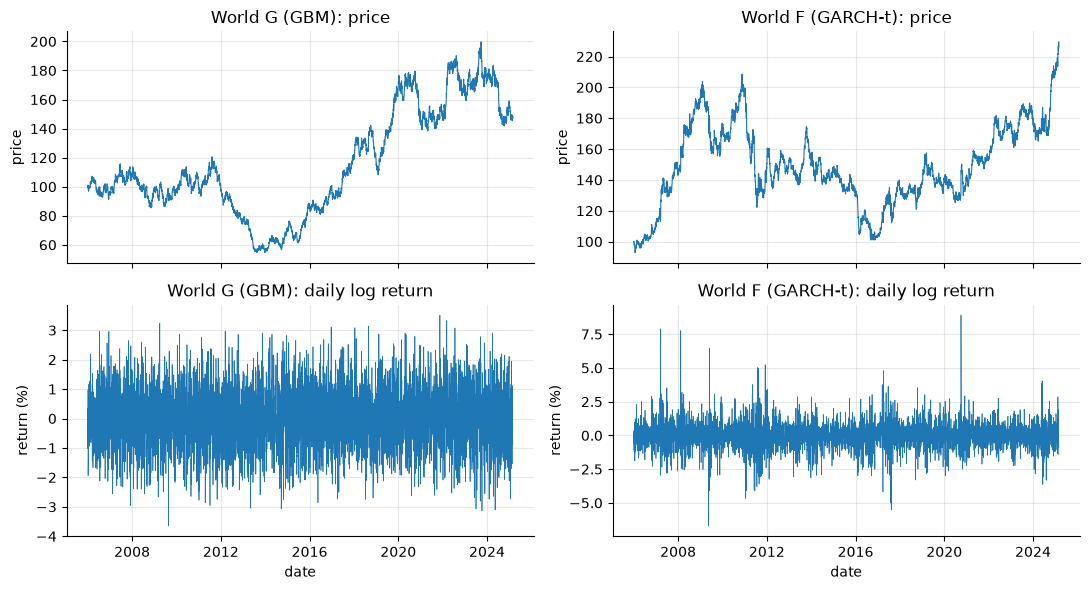

Same drift, same unconditional vol — but World F has visible calm/stormy regimes
ann. vol  G: 0.160   F: 0.151


In [2]:
T = 5_000                       # ~20 years of trading days
MU_ANN, VOL_ANN = 0.07, 0.16
mu_d = MU_ANN / TRADING_DAYS
sig_d = VOL_ANN / np.sqrt(TRADING_DAYS)


def simulate_garch_t(n, mu, sig_uncond, alpha=0.07, beta=0.90, nu=5.0, rng=rng):
    """GARCH(1,1) log returns with unit-variance Student-t innovations.

    Returns (log_returns, true_conditional_sigma). sigma[t] uses info through t-1,
    so it is a genuine one-step-ahead quantity."""
    omega = sig_uncond**2 * (1 - alpha - beta)
    z = rng.standard_t(nu, n) / np.sqrt(nu / (nu - 2))   # E[z]=0, Var[z]=1
    r = np.empty(n)
    sig2 = np.empty(n)
    sig2[0] = sig_uncond**2
    eps = 0.0
    for t in range(n):
        if t > 0:
            sig2[t] = omega + alpha * eps**2 + beta * sig2[t - 1]
        eps = np.sqrt(sig2[t]) * z[t]
        r[t] = mu + eps
    return r, np.sqrt(sig2)


dates = pd.bdate_range("2006-01-02", periods=T)
r_gbm = rng.normal(mu_d, sig_d, T)                       # World G
r_fat, sig_true = simulate_garch_t(T, mu_d, sig_d)       # World F
NU_TRUE = 5.0

px_gbm = pd.Series(100 * np.exp(np.cumsum(r_gbm)), index=dates, name="World G (GBM)")
px_fat = pd.Series(100 * np.exp(np.cumsum(r_fat)), index=dates, name="World F (GARCH-t)")

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for j, (px, r) in enumerate([(px_gbm, r_gbm), (px_fat, r_fat)]):
    axes[0, j].plot(px.index, px.values, lw=0.8)
    axes[0, j].set_title(f"{px.name}: price")
    axes[0, j].set_ylabel("price")
    axes[1, j].plot(px.index, 100 * r, lw=0.5)
    axes[1, j].set_title(f"{px.name}: daily log return")
    axes[1, j].set_ylabel("return (%)")
    axes[1, j].set_xlabel("date")
plt.show()

print("Same drift, same unconditional vol — but World F has visible calm/stormy regimes")
print(f"ann. vol  G: {r_gbm.std()*np.sqrt(TRADING_DAYS):.3f}   F: {r_fat.std()*np.sqrt(TRADING_DAYS):.3f}")

### Verify the aggregation identities numerically

In [3]:
simple_fat = np.exp(r_fat) - 1          # exact simple returns for World F

total_growth = px_fat.iloc[-1] / 100 - 1        # base price is 100 (before the first return)
print("TIME aggregation (World F, full 20y):")
print(f"  true total return                : {total_growth:+.4f}")
print(f"  exp(sum of log returns) - 1      : {np.exp(r_fat.sum()) - 1:+.4f}   (identical)")
print(f"  sum of simple returns (WRONG)    : {simple_fat.sum():+.4f}   (not a return at all)")

# cross-sectional: 50/50 portfolio over one period where A gains 20%, B loses 10%
RA, RB = 0.20, -0.10
port_simple = 0.5 * RA + 0.5 * RB
print("\nASSET aggregation (one period, w = 50/50, A +20%, B -10%):")
print(f"  portfolio simple return          : {port_simple:+.4f}   (exact)")
print(f"  weighted sum of log returns      : {0.5*np.log(1+RA) + 0.5*np.log(1+RB):+.4f}")
print(f"  true portfolio log return        : {np.log(1 + port_simple):+.4f}")
print("  -> log returns are NOT additive across assets; portfolio math needs simple returns")

TIME aggregation (World F, full 20y):
  true total return                : +1.2626
  exp(sum of log returns) - 1      : +1.2626   (identical)
  sum of simple returns (WRONG)    : +1.0430   (not a return at all)

ASSET aggregation (one period, w = 50/50, A +20%, B -10%):
  portfolio simple return          : +0.0500   (exact)
  weighted sum of log returns      : +0.0385
  true portfolio log return        : +0.0488
  -> log returns are NOT additive across assets; portfolio math needs simple returns


## 3. Stylized facts, verified in code

The empirical regularities every returns series shows (Cont, 2001), which any model — and
any interview answer — must respect:

1. **Near-zero autocorrelation of returns** (markets are close to unpredictable at daily
   frequency)…
2. …but **strong, slowly decaying autocorrelation of |returns|** — volatility clusters.
   Returns are dependent *without being correlated*: the classic example of uncorrelated
   ≠ independent.
3. **Fat tails**: excess kurtosis ≫ 0, QQ plots bow away from the normal line.
4. **Aggregational gaussianity**: as you sum daily returns into weekly/monthly returns,
   the distribution drifts back toward normal (a CLT effect, slowed by the vol dependence).

World G will fail facts 2–3 (it's the textbook world); World F reproduces them.
(Real equity returns also show the *leverage effect* — vol rises more after down moves —
which our symmetric GARCH deliberately omits.)

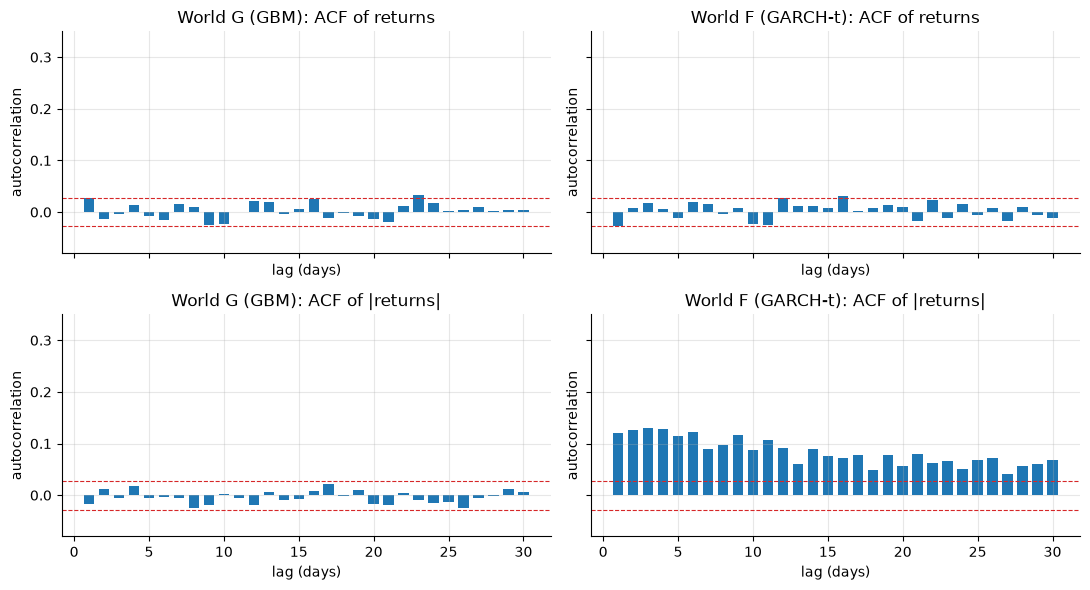

Fact 1+2: returns ~ uncorrelated in BOTH worlds, but only World F has the
slowly-decaying |return| ACF — volatility clustering. Dependence without correlation.


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
lags = np.arange(1, 31)
band = 1.96 / np.sqrt(T)
for j, (name, x) in enumerate([("World G (GBM)", r_gbm), ("World F (GARCH-t)", r_fat)]):
    for i, (lab, series) in enumerate([("returns", x), ("|returns|", np.abs(x))]):
        a = acf(series, nlags=30, fft=True)[1:]
        ax = axes[i, j]
        ax.bar(lags, a, width=0.7)
        ax.axhline(band, ls="--", c="tab:red", lw=0.8)
        ax.axhline(-band, ls="--", c="tab:red", lw=0.8)
        ax.set_title(f"{name}: ACF of {lab}")
        ax.set_ylabel("autocorrelation")
        ax.set_xlabel("lag (days)")
axes[0, 0].set_ylim(-0.08, 0.35)
plt.show()

print("Fact 1+2: returns ~ uncorrelated in BOTH worlds, but only World F has the")
print("slowly-decaying |return| ACF — volatility clustering. Dependence without correlation.")

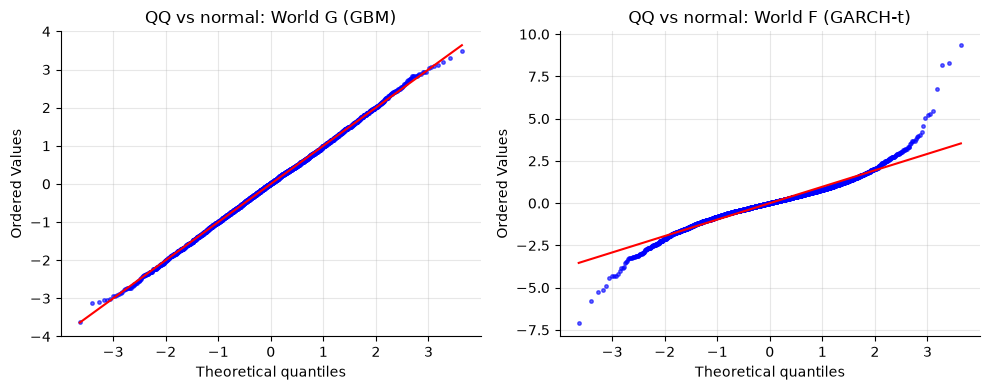

             ann. vol    skew  excess kurtosis  worst day (%)  best day (%)
world                                                                      
G (GBM)        0.1599  0.0021           0.0362        -3.6495        3.5091
F (GARCH-t)    0.1510  0.2937           6.5149        -6.7063        8.9053

Fact 3: World F has large excess kurtosis and daily moves World G never produces.
Note the mechanism is twofold: t(5) shocks AND mixing over regimes of different vol
(even normal-innovation GARCH has fat unconditional tails).


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, x) in zip(axes, [("World G (GBM)", r_gbm), ("World F (GARCH-t)", r_fat)]):
    z = (x - x.mean()) / x.std()
    stats.probplot(z, dist="norm", plot=ax)
    ax.set_title(f"QQ vs normal: {name}")
    ax.get_lines()[0].set(markersize=2.5, alpha=0.6)
plt.show()

moments = pd.DataFrame({
    "world": ["G (GBM)", "F (GARCH-t)"],
    "ann. vol": [x.std() * np.sqrt(TRADING_DAYS) for x in (r_gbm, r_fat)],
    "skew": [stats.skew(x) for x in (r_gbm, r_fat)],
    "excess kurtosis": [stats.kurtosis(x) for x in (r_gbm, r_fat)],
    "worst day (%)": [100 * x.min() for x in (r_gbm, r_fat)],
    "best day (%)": [100 * x.max() for x in (r_gbm, r_fat)],
}).set_index("world")
print(moments)
print("\nFact 3: World F has large excess kurtosis and daily moves World G never produces.")
print("Note the mechanism is twofold: t(5) shocks AND mixing over regimes of different vol")
print("(even normal-innovation GARCH has fat unconditional tails).")

Fact 4 — aggregational gaussianity (World F):
                n obs  excess kurtosis    skew
horizon (days)                                
1                5000           6.5149  0.2937
5                1000           3.1456 -0.0285
21                238           2.7905 -0.2439
63                 79           1.0624 -0.5326


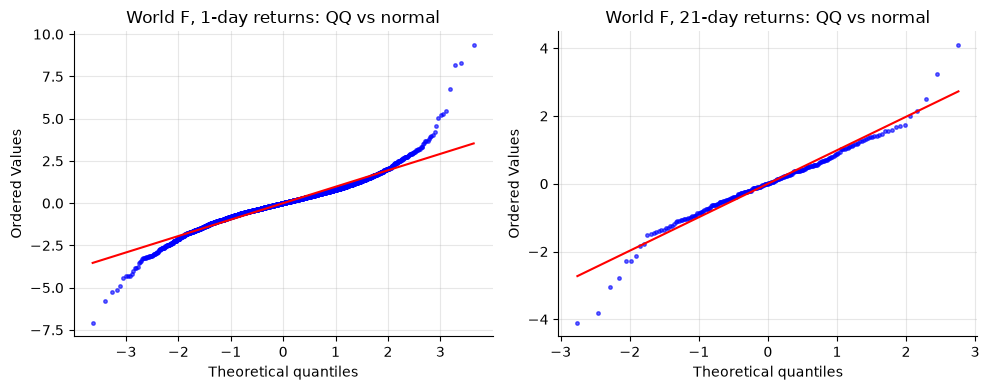

Daily returns are wildly non-normal; quarterly returns are almost respectable.
Horizon determines how much non-normality matters — a key interview point.


In [6]:
rows = []
for h in [1, 5, 21, 63]:
    n = T // h
    agg = r_fat[: n * h].reshape(n, h).sum(axis=1)
    rows.append({"horizon (days)": h, "n obs": n,
                 "excess kurtosis": stats.kurtosis(agg),
                 "skew": stats.skew(agg)})
print("Fact 4 — aggregational gaussianity (World F):")
print(pd.DataFrame(rows).set_index("horizon (days)"))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, h in zip(axes, [1, 21]):
    n = T // h
    agg = r_fat[: n * h].reshape(n, h).sum(axis=1)
    z = (agg - agg.mean()) / agg.std()
    stats.probplot(z, dist="norm", plot=ax)
    ax.set_title(f"World F, {h}-day returns: QQ vs normal")
    ax.get_lines()[0].set(markersize=2.5, alpha=0.6)
plt.show()
print("Daily returns are wildly non-normal; quarterly returns are almost respectable.")
print("Horizon determines how much non-normality matters — a key interview point.")

## 4. Normality understates risk: the price of a 4-sigma day

Standardize returns by their full-sample mean and sd, and ask: how often is a day worse
than −4σ?

- **Normal**: $P(Z < -4) \approx 3.2\times 10^{-5}$ — about once every **125 years**.
- **Student-t / empirical**: orders of magnitude more often.

This is not an academic gap. Sizing leverage, setting margin, or writing options off a
normal tail means being wrong by a large multiple (here ~70x) exactly where it costs the most.
(For calibration: October 19, 1987 was roughly a −20σ day at the then-prevailing vol —
under normality, a once-per-$10^{88}$-years event. The model is what broke, not probability.)

In [7]:
z_fat = (r_fat - r_fat.mean()) / r_fat.std()

p_normal = stats.norm.cdf(-4)
nu_hat, loc_hat, sc_hat = stats.t.fit(r_fat)
p_t_fit = stats.t.cdf(r_fat.mean() - 4 * r_fat.std(), nu_hat, loc_hat, sc_hat)
p_emp = np.mean(z_fat < -4)


def once_every(p):
    if p <= 0:
        return "never observed"
    yrs = 1 / (p * TRADING_DAYS)
    return f"once every {yrs:,.1f} years" if yrs < 10 else f"once every {yrs:,.0f} years"


tail = pd.DataFrame({
    "model": ["normal", f"fitted t (nu={nu_hat:.1f})", "empirical (World F)"],
    "P(day < -4 sigma)": [p_normal, p_t_fit, p_emp],
    "frequency": [once_every(p_normal), once_every(p_t_fit), once_every(p_emp)],
}).set_index("model")
print(tail)
print(f"\nObserved -4 sigma days in {T} days (~20y): {int((z_fat < -4).sum())}")
print(f"Normal model expected: {p_normal * T:.2f}")
print(f"Understatement factor at -4 sigma: {p_emp / p_normal:,.0f}x")

                     P(day < -4 sigma)             frequency
model                                                       
normal                      3.1671e-05  once every 125 years
fitted t (nu=3.8)           2.6563e-03  once every 1.5 years
empirical (World F)         2.2000e-03  once every 1.8 years

Observed -4 sigma days in 5000 days (~20y): 11
Normal model expected: 0.16
Understatement factor at -4 sigma: 69x


## 5. The risk stack: volatility, VaR, Expected Shortfall

### 5.1 Volatility estimation — rolling window vs EWMA, graded against ground truth

- **Rolling window** (e.g. 21 days): equal weight to everything in the window, then a
  hard cliff. Reacts slowly, and a single crash day inflates the estimate for exactly 21
  days then vanishes ("ghosting").
- **EWMA (RiskMetrics)**: $\hat\sigma^2_t = \lambda \hat\sigma^2_{t-1} + (1-\lambda) r_{t-1}^2$
  with $\lambda = 0.94$ — an exponentially-weighted average, i.e. a one-parameter special
  case of GARCH ($\omega=0$, no mean reversion). Industry default for daily risk.

Both are *one-step-ahead* estimates using data through $t-1$ (no look-ahead). Since World F
is simulated we can compare each estimator to the **true** conditional $\sigma_t$.

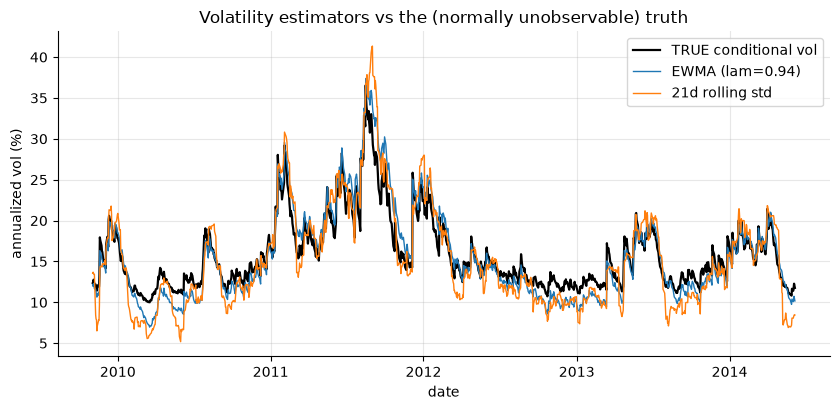

RMSE vs true sigma, EWMA        : 1.69 vol points (annualized)
RMSE vs true sigma, 21d rolling : 2.54 vol points (annualized)


In [8]:
def ewma_vol(r, lam=0.94, init_n=50):
    """RiskMetrics EWMA sigma_t, using returns through t-1 only (one-step-ahead)."""
    sig2 = np.empty(len(r))
    sig2[0] = r[:init_n].var()          # burn-in initialization
    for t in range(1, len(r)):
        sig2[t] = lam * sig2[t - 1] + (1 - lam) * r[t - 1] ** 2
    return np.sqrt(sig2)


ret = pd.Series(r_fat, index=dates, name="ret")
sig_ewma = pd.Series(ewma_vol(r_fat), index=dates)
sig_roll = ret.rolling(21).std().shift(1)     # shift: estimate for day t uses data to t-1
truth = pd.Series(sig_true, index=dates)

ann = np.sqrt(TRADING_DAYS) * 100
sl = slice(1000, 2200)                        # a representative stretch incl. a vol spike
fig, ax = plt.subplots()
ax.plot(truth.index[sl], truth.values[sl] * ann, lw=1.6, label="TRUE conditional vol", c="k")
ax.plot(sig_ewma.index[sl], sig_ewma.values[sl] * ann, lw=1.0, label="EWMA (lam=0.94)")
ax.plot(sig_roll.index[sl], sig_roll.values[sl] * ann, lw=1.0, label="21d rolling std")
ax.set_ylabel("annualized vol (%)")
ax.set_xlabel("date")
ax.set_title("Volatility estimators vs the (normally unobservable) truth")
ax.legend()
plt.show()

mask = ~sig_roll.isna()
for name, est in [("EWMA", sig_ewma[mask]), ("21d rolling", sig_roll[mask])]:
    rmse = np.sqrt(((est - truth[mask]) ** 2).mean()) * ann
    print(f"RMSE vs true sigma, {name:12s}: {rmse:.2f} vol points (annualized)")

### 5.2 VaR three ways, plus Expected Shortfall

One-day Value-at-Risk at level $\alpha$: the loss threshold exceeded with probability
$\alpha$: $P(r_t < -\mathrm{VaR}_\alpha) = \alpha$. Expected Shortfall is the *average*
loss beyond that threshold: $\mathrm{ES}_\alpha = -E[r \mid r < -\mathrm{VaR}_\alpha]$.

Three estimators of the same object:

1. **Parametric normal**: $\mathrm{VaR} = -(\hat\mu + z_\alpha \hat\sigma)$.
2. **Historical**: empirical $\alpha$-quantile of a trailing window. Model-free, but blind
   to anything not in the window and slow to react.
3. **Parametric t**: fit a Student-t (location-scale); the tail index does the work.

First, the *static* full-sample comparison on World F, including the Basel-relevant fact
that under normality ES at 97.5% roughly equals VaR at 99% (which is exactly why FRTB
chose 97.5% ES as the VaR-99 replacement):

In [9]:
def es_from_ppf(ppf, alpha, n_grid=2000):
    """ES_alpha = -(1/alpha) * integral_0^alpha ppf(u) du, midpoint rule."""
    u = (np.arange(n_grid) + 0.5) * alpha / n_grid
    return -np.mean(ppf(u))


mu_hat, sd_hat = r_fat.mean(), r_fat.std()
levels = [0.05, 0.025, 0.01]
rows = []
for a in levels:
    var_n = -(mu_hat + stats.norm.ppf(a) * sd_hat)
    es_n = -mu_hat + sd_hat * stats.norm.pdf(stats.norm.ppf(a)) / a   # closed form
    var_h = -np.quantile(r_fat, a)
    es_h = -r_fat[r_fat <= np.quantile(r_fat, a)].mean()
    var_t = -stats.t.ppf(a, nu_hat, loc_hat, sc_hat)
    es_t = es_from_ppf(lambda u: stats.t.ppf(u, nu_hat, loc_hat, sc_hat), a)
    rows.append({"alpha": a, "VaR normal": var_n, "VaR hist": var_h, "VaR t": var_t,
                 "ES normal": es_n, "ES hist": es_h, "ES t": es_t})
static = pd.DataFrame(rows).set_index("alpha") * 100
print("Static full-sample risk measures, World F (% of portfolio, daily):")
print(static.round(2))
print(f"\nNormal ES@97.5% = {static.loc[0.025, 'ES normal']:.2f}%  vs  normal VaR@99% = "
      f"{static.loc[0.01, 'VaR normal']:.2f}%  (the FRTB calibration)")
print("The further into the tail, the more the normal model lags the t/empirical numbers —")
print("and ES diverges faster than VaR because it integrates the whole tail.")

Static full-sample risk measures, World F (% of portfolio, daily):
       VaR normal  VaR hist  VaR t  ES normal  ES hist  ES t
alpha                                                       
0.050        1.55      1.49   1.42       1.95     2.16  2.17
0.025        1.85      1.91   1.87       2.21     2.65  2.72
0.010        2.20      2.53   2.55       2.52     3.32  3.59

Normal ES@97.5% = 2.21%  vs  normal VaR@99% = 2.20%  (the FRTB calibration)
The further into the tail, the more the normal model lags the t/empirical numbers —
and ES diverges faster than VaR because it integrates the whole tail.


### 5.3 VaR backtesting by exception counting — where normal VaR publicly fails

A 99% one-day VaR model is *supposed* to be exceeded on 1% of days (~2.5 per year). The
basic backtest counts **exceptions** (days with loss > VaR) and asks whether the count is
consistent with 1% — Kupiec's proportion-of-failures likelihood-ratio test. (Basel's
"traffic light" is a coarser version of the same idea.)

We run four honest one-day-ahead models over ~18 years of World F:

- **normal, 500d rolling** window ($\hat\mu, \hat\sigma$)
- **historical, 500d rolling** quantile
- **normal + EWMA vol** (right vol dynamics, wrong tail shape)
- **t + EWMA vol** ($\nu$ fitted once on the first 500 days of EWMA-standardized returns)

The design isolates *two separate failure modes*: stale volatility (rolling windows) and
wrong tail shape (normality).

In [10]:
ALPHA = 0.01
W = 500

roll_mu = ret.rolling(W).mean().shift(1)
roll_sd = ret.rolling(W).std().shift(1)
var_normal_roll = -(roll_mu + stats.norm.ppf(ALPHA) * roll_sd)
var_hist_roll = -ret.rolling(W).quantile(ALPHA).shift(1)
var_normal_ewma = -stats.norm.ppf(ALPHA) * sig_ewma

# fit t tail index once, on EWMA-standardized returns from the first W days
z_std = r_fat / sig_ewma.values
nu_bt, _, sc_bt = stats.t.fit(z_std[:W], floc=0)
var_t_ewma = -stats.t.ppf(ALPHA, nu_bt, 0, sc_bt) * sig_ewma
print(f"tail index fitted on first {W} days: nu = {nu_bt:.2f} (truth: {NU_TRUE:.0f})")

models = {
    "normal, 500d rolling": var_normal_roll,
    "historical, 500d rolling": var_hist_roll,
    "normal + EWMA vol": var_normal_ewma,
    "t + EWMA vol": var_t_ewma,
}


def kupiec_pof(n_exc, n_obs, p=ALPHA):
    """Kupiec unconditional-coverage LR test; returns (LR stat, p-value)."""
    phat = n_exc / n_obs
    ll0 = (n_obs - n_exc) * np.log(1 - p) + n_exc * np.log(p)
    if n_exc == 0:
        ll1 = n_obs * np.log(1 - 1e-12)
    else:
        ll1 = (n_obs - n_exc) * np.log(1 - phat) + n_exc * np.log(phat)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, df=1)


oos = ret.iloc[W:]
rows = []
for name, v in models.items():
    v_oos = v.iloc[W:]
    exc = oos < -v_oos
    x, n = int(exc.sum()), len(oos)
    lr, pval = kupiec_pof(x, n)
    rows.append({
        "model": name, "exceptions": x, "expected": round(n * ALPHA, 1),
        "rate (%)": 100 * x / n, "Kupiec p": pval,
        "avg loss on exc. days (%)": -100 * oos[exc].mean(),
        "avg VaR level (%)": 100 * v_oos.mean(),
    })
bt = pd.DataFrame(rows).set_index("model")
print(f"99% one-day VaR backtest over {len(oos)} days (~{len(oos)/252:.0f}y), World F:")
print(bt.round(4))

tail index fitted on first 500 days: nu = 5.62 (truth: 5)
99% one-day VaR backtest over 4500 days (~18y), World F:
                          exceptions  expected  rate (%)  Kupiec p  \
model                                                                
normal, 500d rolling              88      45.0    1.9556    0.0000   
historical, 500d rolling          60      45.0    1.3333    0.0325   
normal + EWMA vol                 81      45.0    1.8000    0.0000   
t + EWMA vol                      47      45.0    1.0444    0.7661   

                          avg loss on exc. days (%)  avg VaR level (%)  
model                                                                   
normal, 500d rolling                         2.8183             2.1853  
historical, 500d rolling                     3.0417             2.5216  
normal + EWMA vol                            2.5277             2.0697  
t + EWMA vol                                 2.8808             2.3986  


Read the table:

- **normal + rolling window fails twice over** — roughly double the exceptions it promised
  (stale vol *and* thin tails), and Kupiec rejects it decisively.
- **normal + EWMA** fixes the dynamics but still runs ~1.5× the promised exceptions — the
  residual failure is purely the tail shape. With t(5) shocks, the true 1% quantile of a
  unit-variance shock is ≈ 2.61σ, not the normal 2.33σ.
- **historical** and **t + EWMA** are statistically consistent with 1% coverage.
- The "avg loss on exception days" column is a preview of ES: *when* VaR breaks, the loss
  averages well beyond the VaR level. VaR says nothing about that; ES is that number.

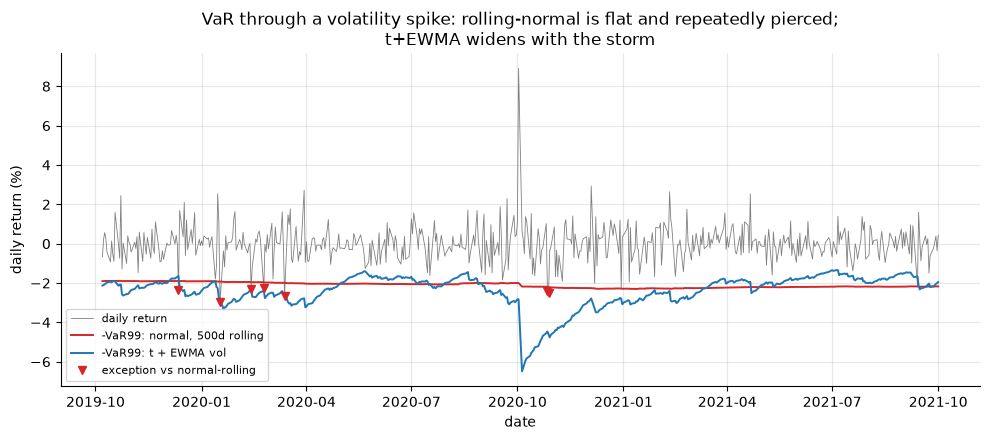

In [11]:
# visualize the failure: VaR lines through the most volatile stretch
peak = int(np.argmax(sig_true))
lo, hi = max(peak - 260, W), peak + 260
seg = ret.iloc[lo:hi]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(seg.index, 100 * seg.values, lw=0.6, c="gray", label="daily return")
for name, c in [("normal, 500d rolling", "tab:red"), ("t + EWMA vol", "tab:blue")]:
    ax.plot(seg.index, -100 * models[name].iloc[lo:hi].values, lw=1.4, label=f"-VaR99: {name}", c=c)
exc_n = seg < -models["normal, 500d rolling"].iloc[lo:hi]
ax.plot(seg.index[exc_n], 100 * seg[exc_n].values, "v", c="tab:red", ms=6,
        label="exception vs normal-rolling")
ax.set_ylabel("daily return (%)")
ax.set_xlabel("date")
ax.set_title("VaR through a volatility spike: rolling-normal is flat and repeatedly pierced;\n"
             "t+EWMA widens with the storm")
ax.legend(loc="lower left", fontsize=8)
plt.show()

## 6. Sharpe ratio: annualization, fragility, and backtest overfitting

### 6.1 Mechanics and standard error

Daily Sharpe $\widehat{SR} = \bar r / s_r$ (excess of funding, ignored here) annualizes as
$\sqrt{252}\,\widehat{SR}$ **only if returns are iid** — autocorrelation breaks the
$\sqrt{h}$ vol scaling (Section 8 demonstrates the trap). And $\widehat{SR}$ is itself a
noisy statistic: under iid normality $\mathrm{se}(\widehat{SR}_{ann}) \approx
\sqrt{(1 + SR^2/2)\cdot 252/T}$ — with skew $\gamma_3$ and kurtosis $\gamma_4$ it becomes
(Mertens/Lo) $\sqrt{(1 + SR^2/2 - \gamma_3 SR + \frac{\gamma_4-3}{4}SR^2)\cdot 252/T}$.
One year of daily data puts a standard error of ~1.0 on an annualized Sharpe. Sit with
that: *most Sharpe differences you will ever be shown are noise.*

In [12]:
def sharpe_ann(r, periods=TRADING_DAYS):
    return r.mean() / r.std() * np.sqrt(periods)


for years in [1, 3, 10, 20]:
    n = years * TRADING_DAYS
    se = np.sqrt(TRADING_DAYS / n)          # iid case, SR^2/2 term negligible at daily scale
    print(f"T = {years:2d}y of daily data -> se(annualized Sharpe) ~ {se:.2f}")

print(f"\nWorld F buy-and-hold: realized ann. Sharpe over 20y = {sharpe_ann(r_fat):.2f} "
      f"(truth: {MU_ANN / VOL_ANN:.2f})")

T =  1y of daily data -> se(annualized Sharpe) ~ 1.00
T =  3y of daily data -> se(annualized Sharpe) ~ 0.58
T = 10y of daily data -> se(annualized Sharpe) ~ 0.32
T = 20y of daily data -> se(annualized Sharpe) ~ 0.22

World F buy-and-hold: realized ann. Sharpe over 20y = 0.27 (truth: 0.44)


### 6.2 Fragility under non-normality: the short-vol illusion

Sharpe compresses a whole distribution into mean/sd; it cannot see *skew*. A strategy that
collects small premia and rarely takes a large loss ("selling insurance", short volatility,
carry) shows a **superb Sharpe in any window that happens to omit the crash** — and those
windows are common. This is the single most reliable way backtests lie.

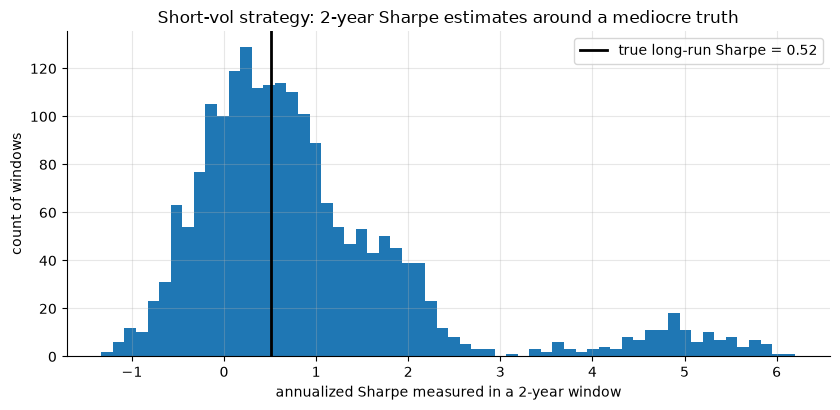

True long-run Sharpe: 0.52 (mediocre)
Share of 2y windows with NO crash day: 7.1% -> those windows show Sharpe ~4.8
Share of windows showing Sharpe > 2: 12.4%
Any Sharpe pitched off a short window demands: what does the return DISTRIBUTION look
like, and what is the exposure that earns the premium?


In [13]:
n_windows, T_win = 2_000, 2 * TRADING_DAYS      # 2-year backtest windows
p_crash, gain_mu, gain_sd, crash_mu = 0.005, 0.0006, 0.002, -0.08

crash = rng.random((n_windows, T_win)) < p_crash
pnl = rng.normal(gain_mu, gain_sd, (n_windows, T_win))
pnl = np.where(crash, rng.normal(crash_mu, 0.01, (n_windows, T_win)), pnl)
sr_windows = pnl.mean(axis=1) / pnl.std(axis=1) * np.sqrt(TRADING_DAYS)

# true long-run Sharpe from the analytic moments of the mixture
mu_true = (1 - p_crash) * gain_mu + p_crash * crash_mu
ex2 = (1 - p_crash) * (gain_mu**2 + gain_sd**2) + p_crash * (crash_mu**2 + 0.01**2)
sr_true = mu_true / np.sqrt(ex2 - mu_true**2) * np.sqrt(TRADING_DAYS)

fig, ax = plt.subplots()
ax.hist(sr_windows, bins=60)
ax.axvline(sr_true, c="k", lw=2, label=f"true long-run Sharpe = {sr_true:.2f}")
ax.set_xlabel("annualized Sharpe measured in a 2-year window")
ax.set_ylabel("count of windows")
ax.set_title("Short-vol strategy: 2-year Sharpe estimates around a mediocre truth")
ax.legend()
plt.show()

no_crash = (~crash.any(axis=1)).mean()
print(f"True long-run Sharpe: {sr_true:.2f} (mediocre)")
print(f"Share of 2y windows with NO crash day: {no_crash:.1%} "
      f"-> those windows show Sharpe ~{sr_windows[~crash.any(axis=1)].mean():.1f}")
print(f"Share of windows showing Sharpe > 2: {(sr_windows > 2).mean():.1%}")
print("Any Sharpe pitched off a short window demands: what does the return DISTRIBUTION look")
print("like, and what is the exposure that earns the premium?")

### 6.3 THE demonstration: 1000 random strategies and the collapse of the best one

Backtest overfitting is **multiple testing wearing a Patagonia vest**. Generate 1000
strategies with *zero true edge* (pure noise daily P&L), give each a 5-year in-sample
backtest, and select the best in-sample Sharpe. It looks fundable. Then trade it for the
next 2 years.

This is the same selection-on-noise mechanism as scanning 100 subgroups for significance
(see [../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb))
— the max of $N$ noisy estimates is biased upward by an amount you can compute.

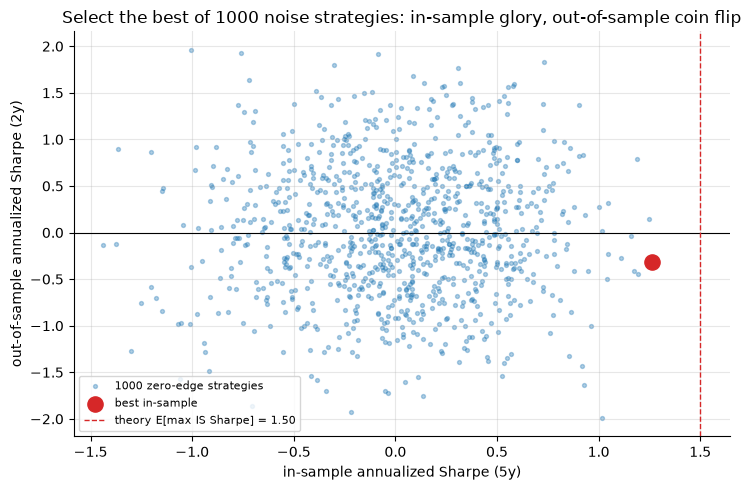

Best strategy:  IS Sharpe = 1.26   OOS Sharpe = -0.31
Theory expected max of 1000 zero-edge Sharpes: 1.50 -> selection alone fully explains the winner
Top-20 in-sample strategies: mean IS = 1.05, mean OOS = -0.24
Correlation(IS, OOS) across all strategies: +0.014
Selection created the Sharpe; nothing was there to persist.


In [14]:
n_strat, T_is, T_oos = 1_000, 5 * TRADING_DAYS, 2 * TRADING_DAYS
pnl_all = rng.normal(0.0, 0.01, (n_strat, T_is + T_oos))   # zero-edge strategies

sr_is = pnl_all[:, :T_is].mean(1) / pnl_all[:, :T_is].std(1) * np.sqrt(TRADING_DAYS)
sr_oos = pnl_all[:, T_is:].mean(1) / pnl_all[:, T_is:].std(1) * np.sqrt(TRADING_DAYS)
best = int(np.argmax(sr_is))
top20 = np.argsort(sr_is)[-20:]

# expected maximum Sharpe among N zero-edge trials (Bailey & Lopez de Prado)
EULER_GAMMA = 0.5772156649


def expected_max_sharpe(n_trials, sr_variance):
    """E[max of n_trials zero-mean Sharpes], per-period units; sr_variance = Var(SR_hat)."""
    return np.sqrt(sr_variance) * (
        (1 - EULER_GAMMA) * stats.norm.ppf(1 - 1 / n_trials)
        + EULER_GAMMA * stats.norm.ppf(1 - 1 / (n_trials * np.e)))


sr_var_daily = np.var(sr_is / np.sqrt(TRADING_DAYS))
emax_ann = expected_max_sharpe(n_strat, sr_var_daily) * np.sqrt(TRADING_DAYS)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(sr_is, sr_oos, s=8, alpha=0.35, label="1000 zero-edge strategies")
ax.scatter(sr_is[best], sr_oos[best], s=120, c="tab:red", zorder=5, label="best in-sample")
ax.axhline(0, c="k", lw=0.8)
ax.axvline(emax_ann, c="tab:red", ls="--", lw=1,
           label=f"theory E[max IS Sharpe] = {emax_ann:.2f}")
ax.set_xlabel("in-sample annualized Sharpe (5y)")
ax.set_ylabel("out-of-sample annualized Sharpe (2y)")
ax.set_title("Select the best of 1000 noise strategies: in-sample glory, out-of-sample coin flip")
ax.legend(fontsize=8)
plt.show()

print(f"Best strategy:  IS Sharpe = {sr_is[best]:.2f}   OOS Sharpe = {sr_oos[best]:+.2f}")
print(f"Theory expected max of 1000 zero-edge Sharpes: {emax_ann:.2f} "
      "-> selection alone fully explains the winner")
print(f"Top-20 in-sample strategies: mean IS = {sr_is[top20].mean():.2f}, "
      f"mean OOS = {sr_oos[top20].mean():+.2f}")
print(f"Correlation(IS, OOS) across all strategies: {np.corrcoef(sr_is, sr_oos)[0,1]:+.3f}")
print("Selection created the Sharpe; nothing was there to persist.")

### 6.4 Deflated Sharpe ratio: the multiple-testing correction, quantified

The **Probabilistic Sharpe Ratio** (Bailey & López de Prado) is the probability that the
true Sharpe exceeds a benchmark $SR_0$, accounting for estimation noise, skew and kurtosis:

$$PSR(SR_0) = \Phi\!\left(\frac{(\widehat{SR}-SR_0)\sqrt{T-1}}
{\sqrt{1-\gamma_3\widehat{SR} + \frac{\gamma_4-1}{4}\widehat{SR}^2}}\right)$$

(per-period units). The **Deflated Sharpe Ratio** sets $SR_0$ = the expected max Sharpe of
your $N$ trials under zero edge — the number we just computed. Same logic as a Bonferroni
haircut: your winner must clear the bar that pure selection already guarantees. Harvey &
Liu's "Sharpe haircut" is the same idea run through multiple-testing p-value corrections.

In [15]:
def probabilistic_sharpe(sr_hat, sr0, n_obs, skew, kurt_raw):
    """PSR in per-period (daily) Sharpe units; kurt_raw is non-excess kurtosis (normal=3)."""
    denom = np.sqrt(1 - skew * sr_hat + (kurt_raw - 1) / 4 * sr_hat**2)
    return stats.norm.cdf((sr_hat - sr0) * np.sqrt(n_obs - 1) / denom)


best_is = pnl_all[best, :T_is]
sr_d = best_is.mean() / best_is.std()
g3 = stats.skew(best_is)
g4 = stats.kurtosis(best_is, fisher=False)
sr0_daily = expected_max_sharpe(n_strat, sr_var_daily)

psr_naive = probabilistic_sharpe(sr_d, 0.0, T_is, g3, g4)
dsr = probabilistic_sharpe(sr_d, sr0_daily, T_is, g3, g4)

print(f"Winner's IS Sharpe (ann.):                {sr_is[best]:.2f}")
print(f"PSR vs SR0=0   (ignores the 1000 trials): {psr_naive:.4f}  <- 'highly significant!'")
print(f"DSR vs SR0=E[max of 1000 trials]:         {dsr:.4f}  <- no evidence of skill at all")
print("\nThe only difference between euphoria and a shrug is honestly counting N.")
print("Interview soundbite: 'a backtested Sharpe is a test statistic, and its null")
print("distribution depends on how many things were tried.'")

Winner's IS Sharpe (ann.):                1.26
PSR vs SR0=0   (ignores the 1000 trials): 0.9975  <- 'highly significant!'
DSR vs SR0=E[max of 1000 trials]:         0.2977  <- no evidence of skill at all

The only difference between euphoria and a shrug is honestly counting N.
Interview soundbite: 'a backtested Sharpe is a test statistic, and its null
distribution depends on how many things were tried.'


## 7. Diversification: covariance math and risk contributions

Portfolio variance with weights $w$ and covariance $\Sigma$: $\sigma_p^2 = w^\top \Sigma w$.
Because $\sigma_p(w)$ is homogeneous of degree 1, Euler's theorem decomposes it exactly:

$$\sigma_p = \sum_i \underbrace{w_i \cdot \frac{(\Sigma w)_i}{\sigma_p}}_{\text{risk contribution } RC_i}$$

Capital weights and **risk** weights can be wildly different — the classic senior-level
gotcha. A 4-asset "diversified" 25/25/25/25 book:

asset vols (ann.): {'US equity': np.float64(0.168), 'Intl equity': np.float64(0.165), 'Tech tilt': np.float64(0.27), 'Bonds': np.float64(0.046)}

correlation matrix:
             US equity  Intl equity  Tech tilt  Bonds
US equity         1.00         0.83       0.79   0.17
Intl equity       0.83         1.00       0.73   0.15
Tech tilt         0.79         0.73       1.00   0.15
Bonds             0.17         0.15       0.15   1.00

portfolio vol: 0.142  (avg standalone vol: 0.162)
             capital weight    vol  risk contribution  share of risk
US equity              0.25  0.168              0.039          0.275
Intl equity            0.25  0.165              0.037          0.261
Tech tilt              0.25  0.270              0.063          0.445
Bonds                  0.25  0.046              0.003          0.020


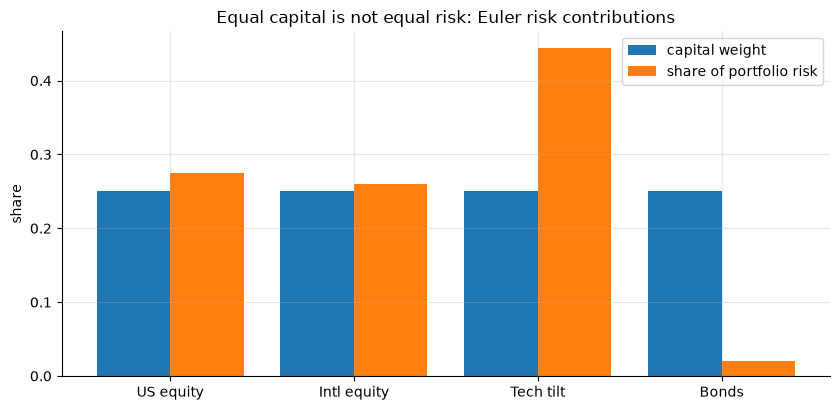

Bonds are 25% of capital and ~2% of risk; the tech tilt alone is ~45% of risk.
'Where is the risk in this book?' means THIS decomposition, not the weights.


In [16]:
names = ["US equity", "Intl equity", "Tech tilt", "Bonds"]
beta = np.array([1.00, 0.90, 1.40, 0.05])       # loadings on a market factor
sig_m = 0.16                                     # market factor vol (annual)
idio = np.array([0.05, 0.08, 0.15, 0.045])       # idiosyncratic vols (annual)
Sigma = np.outer(beta, beta) * sig_m**2 + np.diag(idio**2)

vols = np.sqrt(np.diag(Sigma))
corr = Sigma / np.outer(vols, vols)
print("asset vols (ann.):", dict(zip(names, vols.round(3))))
print("\ncorrelation matrix:")
print(pd.DataFrame(corr, index=names, columns=names).round(2))

w4 = np.full(4, 0.25)
port_vol = np.sqrt(w4 @ Sigma @ w4)
mrc = Sigma @ w4 / port_vol            # marginal risk contributions
rc = w4 * mrc                          # Euler risk contributions; sum == port_vol
summary = pd.DataFrame({"capital weight": w4, "vol": vols,
                        "risk contribution": rc, "share of risk": rc / port_vol},
                       index=names)
print(f"\nportfolio vol: {port_vol:.3f}  (avg standalone vol: {vols.mean():.3f})")
print(summary.round(3))
assert np.isclose(rc.sum(), port_vol)

fig, ax = plt.subplots()
x = np.arange(4)
ax.bar(x - 0.2, w4, width=0.4, label="capital weight")
ax.bar(x + 0.2, rc / port_vol, width=0.4, label="share of portfolio risk")
ax.set_xticks(x, names)
ax.set_ylabel("share")
ax.set_title("Equal capital is not equal risk: Euler risk contributions")
ax.legend()
plt.show()
print("Bonds are 25% of capital and ~2% of risk; the tech tilt alone is ~45% of risk.")
print("'Where is the risk in this book?' means THIS decomposition, not the weights.")

### Correlation caps the benefit — and rises exactly when you need it not to

For $n$ equal-weight assets with common vol $\sigma$ and pairwise correlation $\rho$:
$\sigma_p^2 = \sigma^2\left(\tfrac{1}{n} + (1-\tfrac1n)\rho\right) \to \rho\,\sigma^2$.
Idiosyncratic risk diversifies away; **systematic risk does not** — the floor is
$\sigma\sqrt{\rho}$ no matter how many assets you add. Worse, equity correlations are
regime-dependent: they jump in stress, so the floor is highest on the worst days.

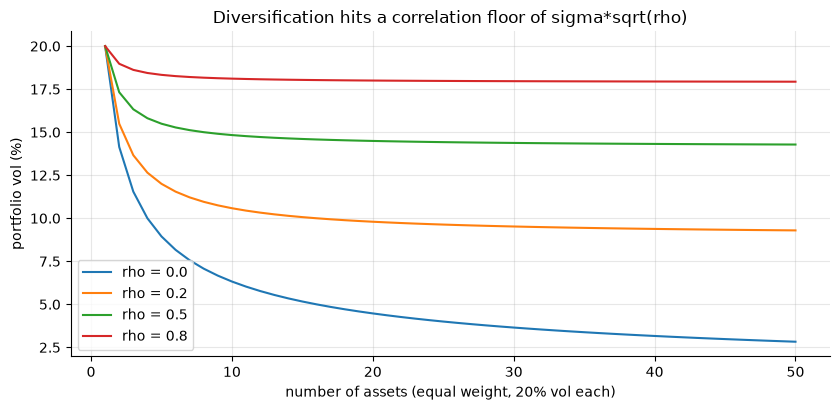

correlation, calm days   : 0.35
correlation, stress days : 0.70
correlation, full sample : 0.51
A full-sample correlation matrix quietly averages regimes; tail hedging priced off it
will disappoint. This is why 'diversification failed in 2008' is not a paradox.


In [17]:
fig, ax = plt.subplots()
ns = np.arange(1, 51)
for rho in [0.0, 0.2, 0.5, 0.8]:
    pv = 0.20 * np.sqrt(1 / ns + (1 - 1 / ns) * rho)
    ax.plot(ns, 100 * pv, label=f"rho = {rho}")
ax.set_xlabel("number of assets (equal weight, 20% vol each)")
ax.set_ylabel("portfolio vol (%)")
ax.set_title("Diversification hits a correlation floor of sigma*sqrt(rho)")
ax.legend()
plt.show()

# stress-dependent correlation demo: shared factor gets violent on 5% of days
n_days = 5_000
stress = rng.random(n_days) < 0.05
f = np.where(stress, rng.normal(-0.02, 0.012, n_days), rng.normal(0.0004, 0.006, n_days))
x1 = f + rng.normal(0, 0.008, n_days)
x2 = f + rng.normal(0, 0.008, n_days)
print(f"correlation, calm days   : {np.corrcoef(x1[~stress], x2[~stress])[0,1]:.2f}")
print(f"correlation, stress days : {np.corrcoef(x1[stress], x2[stress])[0,1]:.2f}")
print(f"correlation, full sample : {np.corrcoef(x1, x2)[0,1]:.2f}")
print("A full-sample correlation matrix quietly averages regimes; tail hedging priced off it")
print("will disappoint. This is why 'diversification failed in 2008' is not a paradox.")

## 8. Pitfalls (each demonstrated)

### Pitfall 1 — Arithmetic mean ≠ growth: volatility drag and leverage

Expected *growth* is $g \approx \mu - \sigma^2/2$ (in log terms), not $\mu$. Levering a
position by $L$ multiplies $\mu$ by $L$ but the drag by $L^2$: realized compound growth is
a *parabola* in leverage, and past the peak more leverage destroys wealth with a positive
arithmetic edge. Fat tails pull the true optimum below the Gaussian formula.

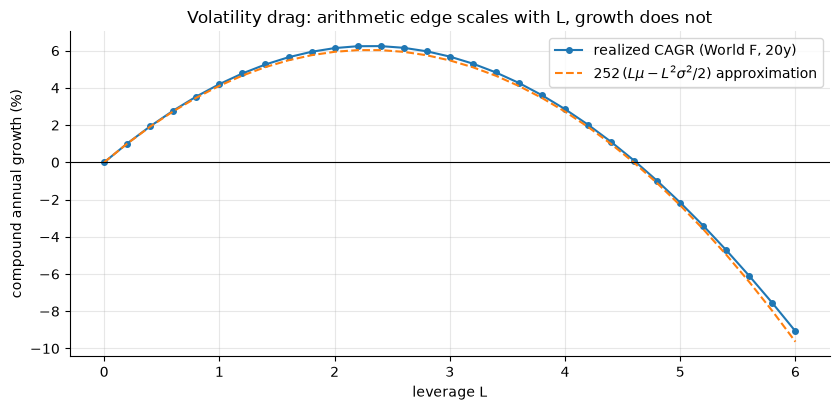

Arithmetic expected return at L=4: 21.0% per year — looks great.
Realized compound growth at L=4:  +2.9% per year.
Growth-optimal leverage here ~ 2.4; Gaussian formula says 2.3.


In [18]:
levs = np.linspace(0, 6, 31)
m_s, s_s = simple_fat.mean(), simple_fat.std()
cagr = []
for L in levs:
    wealth_path = 1 + L * simple_fat
    if (wealth_path <= 0).any():
        cagr.append(-1.0)                       # levered into ruin
    else:
        cagr.append(np.exp(np.log(wealth_path).sum() / T * TRADING_DAYS) - 1)
cagr = np.array(cagr)
approx = TRADING_DAYS * (levs * m_s - (levs * s_s) ** 2 / 2)

fig, ax = plt.subplots()
ax.plot(levs, 100 * cagr, "o-", ms=4, label="realized CAGR (World F, 20y)")
ax.plot(levs, 100 * approx, "--", label=r"$252\,(L\mu - L^2\sigma^2/2)$ approximation")
ax.axhline(0, c="k", lw=0.8)
ax.set_xlabel("leverage L")
ax.set_ylabel("compound annual growth (%)")
ax.set_title("Volatility drag: arithmetic edge scales with L, growth does not")
ax.legend()
plt.show()
best_L = levs[np.argmax(cagr)]
print(f"Arithmetic expected return at L=4: {TRADING_DAYS * 4 * m_s:.1%} per year — looks great.")
print(f"Realized compound growth at L=4:  {cagr[levs.searchsorted(4.0)]:+.1%} per year.")
print(f"Growth-optimal leverage here ~ {best_L:.1f}; Gaussian formula says {m_s / s_s**2:.1f}.")

### Pitfall 2 — Smoothed (stale-priced) returns inflate Sharpe, and √252 lies

Illiquid or appraisal-based assets (private equity, real estate, some credit) report
returns that are *smoothed*: $r^{obs}_t = (1-\theta) r_t + \theta\, r^{obs}_{t-1}$.
Smoothing shrinks measured vol by $\sqrt{(1-\theta)/(1+\theta)}$ while barely touching the
mean — measured Sharpe inflates mechanically. It also induces positive autocorrelation,
which breaks the $\sqrt{252}$ annualization (Lo 2002). The fix: annualize with the
autocorrelation-adjusted scale.

In [19]:
theta = 0.6
r_obs = np.empty(T)
r_obs[0] = r_fat[0]
for t in range(1, T):
    r_obs[t] = (1 - theta) * r_fat[t] + theta * r_obs[t - 1]


def lo_annualized_sharpe(r, q=TRADING_DAYS, max_lag=20):
    """Lo (2002): SR(q) = q * SR_1 / sqrt(q + 2*sum_k (q-k) rho_k)."""
    sr1 = r.mean() / r.std()
    rho = acf(r, nlags=max_lag, fft=True)[1:]
    return q * sr1 / np.sqrt(q + 2 * np.sum((q - np.arange(1, max_lag + 1)) * rho))


print(f"true asset:      ann vol {r_fat.std()*np.sqrt(252):.1%}, "
      f"naive ann Sharpe {sharpe_ann(r_fat):.2f}")
print(f"smoothed report: ann vol {r_obs.std()*np.sqrt(252):.1%}, "
      f"naive ann Sharpe {sharpe_ann(r_obs):.2f}  <- 'half the vol, double the Sharpe!'")
print(f"lag-1 autocorrelation of smoothed series: {acf(r_obs, nlags=1, fft=True)[1]:.2f} "
      f"(theory: theta = {theta})")
print(f"Lo-adjusted ann Sharpe of smoothed series: {lo_annualized_sharpe(r_obs):.2f} "
      f"(vs true {sharpe_ann(r_fat):.2f})")
print("\nPositive autocorrelation => sqrt(252) over-annualizes. Any suspiciously smooth NAV")
print("series with fat Sharpe deserves an autocorrelation check before admiration.")

true asset:      ann vol 15.1%, naive ann Sharpe 0.27
smoothed report: ann vol 7.5%, naive ann Sharpe 0.55  <- 'half the vol, double the Sharpe!'
lag-1 autocorrelation of smoothed series: 0.59 (theory: theta = 0.6)
Lo-adjusted ann Sharpe of smoothed series: 0.25 (vs true 0.27)

Positive autocorrelation => sqrt(252) over-annualizes. Any suspiciously smooth NAV
series with fat Sharpe deserves an autocorrelation check before admiration.


### Pitfall 3 — Historical VaR's window mechanics: blind before, haunted after

A rolling historical quantile cannot exceed anything it hasn't seen: before a crash it is
oblivious, and afterwards the crash days sit in the window inflating VaR for *exactly*
`W` days — then fall off a cliff ("ghosting"), often just as memories fade. Risk estimates
inherit the window, not the world.

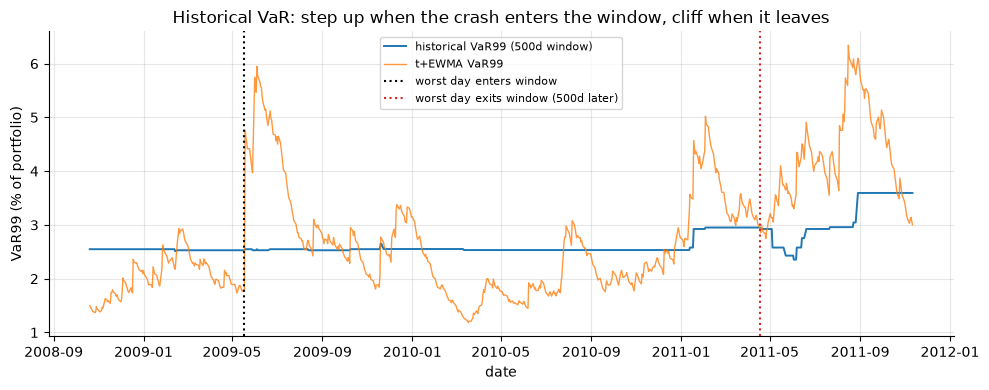

Nothing happened in markets on the red dotted date — the model just forgot.
EWMA/GARCH decay memory smoothly; historical windows decay it as a step function.


In [20]:
crash_day = int(np.argmin(r_fat))
lo2, hi2 = max(crash_day - 150, W), min(crash_day + W + 150, T)
seg2 = slice(lo2, hi2)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates[seg2], 100 * var_hist_roll.iloc[seg2], lw=1.4,
        label=f"historical VaR99 ({W}d window)")
ax.plot(dates[seg2], 100 * var_t_ewma.iloc[seg2], lw=1.0, alpha=0.8, label="t+EWMA VaR99")
ax.axvline(dates[crash_day], c="k", ls=":", label="worst day enters window")
ax.axvline(dates[min(crash_day + W, T - 1)], c="tab:red", ls=":",
           label=f"worst day exits window ({W}d later)")
ax.set_ylabel("VaR99 (% of portfolio)")
ax.set_xlabel("date")
ax.set_title("Historical VaR: step up when the crash enters the window, cliff when it leaves")
ax.legend(fontsize=8)
plt.show()
print("Nothing happened in markets on the red dotted date — the model just forgot.")
print("EWMA/GARCH decay memory smoothly; historical windows decay it as a step function.")

## 9. Interview corner

**Q1. VaR vs Expected Shortfall — and why did regulation move (Basel FRTB)?**
VaR$_\alpha$ is a tail *quantile* ("the loss exceeded 1% of the time"); ES$_\alpha$ is the
*mean loss beyond it*. Strong answer hits: (1) VaR says nothing about severity beyond the
threshold, so it can be gamed — sell deep out-of-the-money options and losses concentrate
past the quantile, VaR unchanged; (2) VaR is not subadditive in general (merging desks can
*raise* measured risk), ES is coherent, so ES aggregates sanely across a firm; (3) ES is
sensitive to tail shape, exactly what Section 5.2 showed diverging under fat tails.
Trade-off a senior candidate volunteers: ES is harder to backtest (it is not elicitable on
its own; exception counting doesn't directly test it) and has higher estimation variance —
regulators accepted that cost, moving FRTB to 97.5% ES, calibrated to match 99% VaR under
normality.

**Q2. A backtest shows Sharpe 3. What questions do you ask?**
In order: (1) *How many things were tried* — strategies, parameter sets, universes,
start dates? That sets the null via E[max] (Section 6.3-6.4); demand the deflated Sharpe.
(2) Costs and capacity: after transaction costs, borrow, slippage at intended size?
(3) Data hygiene: look-ahead (restated fundamentals, index membership), survivorship bias
in the universe? (4) Out-of-sample discipline: was the "OOS" period consulted more than
once? A reused OOS set is in-sample. (5) Distribution: skew/kurtosis — is it short-vol
(Section 6.2)? What's the worst plausible month? (6) Regime coverage: does the sample
include a rate cycle / vol spike / liquidity event? (7) Why does the edge exist and who is
on the other side — an economic prior, because with enough trials noise alone produces
Sharpe 3.

**Q3. Why do returns violate normality, and when does it actually matter?**
Mechanisms: (a) volatility clustering — the unconditional distribution is a *mixture* of
normals with different variances, which is automatically fat-tailed; (b) genuinely
heavy-tailed shocks (news, jumps, liquidity cascades) — even vol-standardized returns stay
fat (our t(5) innovations); (c) crowding/feedback in crises. When it matters: tail
probabilities (Section 4: 4σ events ~70× more likely than normal admits), VaR/ES, leverage sizing and
margin, option pricing (smiles exist because Black-Scholes assumes GBM), short horizons.
When it matters less: long-horizon aggregates (aggregational gaussianity, Section 3),
questions about means rather than tails, large-portfolio CLT-ish averages. Senior nuance:
"returns aren't normal" ≠ "nothing is normal" — *conditionally* normal with time-varying
vol captures much of it, but not all (hence t innovations).

**Q4. How would you backtest a VaR model?**
Exception counting first: at 99%/1-day expect 1% exceptions; Kupiec LR for unconditional
coverage (Section 5.3). Then *independence*: exceptions should not cluster — Christoffersen's
test on exception runs; clustered exceptions mean vol dynamics are wrong even if the count
is right. Mention the Basel traffic-light zones as the regulatory version, and the
asymmetry: with ~2.5 expected exceptions/year you have low power — it takes years to
statistically reject a bad model, which is itself a talking point.

**Q5. Your book is equal-weighted but someone says 90% of the risk is one position. What do
they mean?**
Euler decomposition of portfolio vol: $RC_i = w_i(\Sigma w)_i/\sigma_p$, summing exactly to
$\sigma_p$ (Section 7). High-vol, high-correlation positions dominate risk regardless of
capital weights. Follow-ups to expect: risk parity (choose $w$ to equalize $RC_i$ — Exercise
3), and the caveat that $\Sigma$ is estimated (noisy, regime-dependent), so risk
contributions are estimates too.

**Q6. Simple vs log returns — when does the choice actually bite?**
The two aggregation identities (Section 1): time-compounding wants log, portfolio math
wants simple. Bites when: multi-period compounding at high vol (volatility drag, Pitfall
1 — arithmetic mean of ±50% coin is 0, you still lose 13% per flip pair), leverage
decisions, long-horizon projections from daily means, and any code path that averages log
returns across assets to make a "portfolio return."

## 10. Key takeaways

- Log returns add over time, simple returns add over assets; using the wrong one is a bug,
  and at high vol/leverage an expensive one (drag $\approx \sigma^2/2$).
- Real(istic) returns: uncorrelated but not independent — |returns| are strongly
  autocorrelated (vol clustering), tails are fat, and non-normality fades with aggregation
  horizon.
- The normal model understates a 4σ day by a factor of ~70 here; the fix (t tails and/or
  dynamic vol) is cheap, so "we assumed normal for simplicity" is a weak answer where tails
  carry the cost.
- EWMA (λ=0.94) tracks true conditional vol far better than same-length rolling windows;
  it's a degenerate GARCH and the industry workhorse.
- Backtest your VaR: count exceptions, test coverage (Kupiec) and clustering. Parametric-
  normal VaR fails loudly in a fat-tailed world; historical and t versions hold coverage.
- ES > VaR as a risk summary (severity, coherence, tail sensitivity) at the cost of harder
  backtesting — that trade is why FRTB moved to 97.5% ES.
- An annualized Sharpe from one year of daily data has a standard error near 1.0. Most
  Sharpe rankings you'll see are noise.
- The best of N zero-edge backtests has expected Sharpe $\approx \sqrt{2\ln N}\cdot se$ —
  selection manufactures performance. Deflate by E[max] (DSR) or refuse to evaluate a
  backtest without knowing N.
- Equal capital ≠ equal risk: Euler risk contributions locate the risk; correlation sets a
  floor $\sigma\sqrt{\rho}$ on diversification and rises in stress.

## 11. Exercises

**Exercise 1.** Repeat the VaR exception backtest of Section 5.3 at α = 5%, 1%, and 0.1%
for the *normal+EWMA*, *t+EWMA* and *historical* models. Compute the ratio of realized to
promised exception rates. Where in the tail does the normal model break down, and what
structural problem does the historical model hit at α = 0.1% with a 500-day window?

In [21]:
# --- Solution ---
rows = []
for a in [0.05, 0.01, 0.001]:
    v_n = -stats.norm.ppf(a) * sig_ewma
    v_t = -stats.t.ppf(a, nu_bt, 0, sc_bt) * sig_ewma
    v_h = -ret.rolling(W).quantile(a).shift(1)
    for name, v in [("normal+EWMA", v_n), ("t+EWMA", v_t), ("historical 500d", v_h)]:
        exc_rate = (oos < -v.iloc[W:]).mean()
        rows.append({"alpha": a, "model": name, "realized rate": exc_rate,
                     "realized / promised": exc_rate / a})
ex1 = pd.DataFrame(rows).pivot(index="model", columns="alpha", values="realized / promised")
print("Realized / promised exception ratio (1.0 = perfect coverage):")
print(ex1.round(2))
print("\nNormal+EWMA degrades monotonically as alpha shrinks: at 5% the normal quantile is")
print("nearly right; at 0.1% it is far too shallow — tail-shape error grows into the tail.")
print("Historical at 0.1% needs the 0.5th smallest of 500 points: it interpolates at the")
print("window minimum, so the estimate is dominated by 1-2 observations — huge variance.")
print("Rule of thumb: historical VaR needs ~ 10/alpha observations to be usable.")

Realized / promised exception ratio (1.0 = perfect coverage):
alpha            0.001  0.010  0.050
model                               
historical 500d   2.67   1.33   1.06
normal+EWMA       5.33   1.80   1.06
t+EWMA            0.89   1.04   1.06

Normal+EWMA degrades monotonically as alpha shrinks: at 5% the normal quantile is
nearly right; at 0.1% it is far too shallow — tail-shape error grows into the tail.
Historical at 0.1% needs the 0.5th smallest of 500 points: it interpolates at the
window minimum, so the estimate is dominated by 1-2 observations — huge variance.
Rule of thumb: historical VaR needs ~ 10/alpha observations to be usable.


**Exercise 2.** Your team backtested N strategy variants (grid-searching parameters counts!)
on 5 years of daily data. Plot the expected maximum *annualized* in-sample Sharpe of pure
noise as a function of N from 10 to 100,000. What Sharpe should impress you if N = 10,000?

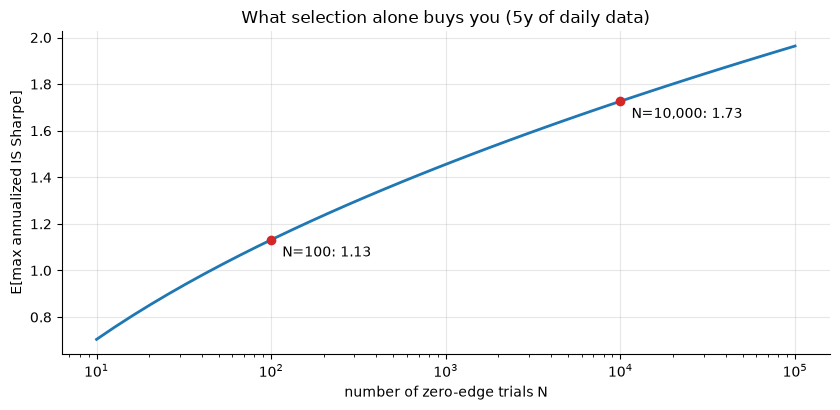

At N = 10,000 trials, noise alone delivers an expected best Sharpe of about 1.73.
So a grid-searched 'Sharpe 2' on 5 years of data is roughly the null expectation —
the impressive number is the one that clears E[max] with room to spare (DSR near 1).


In [22]:
# --- Solution ---
Ns = np.logspace(1, 5, 40)
emax = np.array([expected_max_sharpe(n, 1 / T_is) for n in Ns]) * np.sqrt(TRADING_DAYS)
fig, ax = plt.subplots()
ax.semilogx(Ns, emax, lw=2)
for n_mark in [100, 10_000]:
    e = expected_max_sharpe(n_mark, 1 / T_is) * np.sqrt(TRADING_DAYS)
    ax.plot(n_mark, e, "o", c="tab:red")
    ax.annotate(f"N={n_mark:,}: {e:.2f}", (n_mark, e), textcoords="offset points",
                xytext=(8, -12))
ax.set_xlabel("number of zero-edge trials N")
ax.set_ylabel("E[max annualized IS Sharpe]")
ax.set_title("What selection alone buys you (5y of daily data)")
plt.show()
print("At N = 10,000 trials, noise alone delivers an expected best Sharpe of about "
      f"{expected_max_sharpe(10_000, 1/T_is)*np.sqrt(252):.2f}.")
print("So a grid-searched 'Sharpe 2' on 5 years of data is roughly the null expectation —")
print("the impressive number is the one that clears E[max] with room to spare (DSR near 1).")

**Exercise 3.** Using the 4-asset covariance matrix from Section 7, find **risk-parity**
weights: long-only weights summing to 1 with equal Euler risk contributions. Compare the
weights, portfolio vol, and risk shares to the equal-weight book.

In [23]:
# --- Solution ---
def rc_dispersion(w):
    rc_ = w * (Sigma @ w)                       # contributions to variance
    return 1e6 * np.sum((rc_ - rc_.mean()) ** 2)


res = minimize(rc_dispersion, np.full(4, 0.25), method="SLSQP",
               bounds=[(1e-4, 1.0)] * 4,
               constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
w_rp = res.x
vol_rp = np.sqrt(w_rp @ Sigma @ w_rp)
rc_rp = w_rp * (Sigma @ w_rp) / vol_rp

ex3 = pd.DataFrame({"equal weight": w4, "risk-parity weight": w_rp,
                    "EW risk share": rc / port_vol, "RP risk share": rc_rp / vol_rp},
                   index=names)
print(ex3.round(3))
print(f"\nportfolio vol: equal weight {port_vol:.3f}  vs  risk parity {vol_rp:.3f}")
print("Risk parity loads up on bonds (low vol, near-zero correlation) and cuts the tech")
print("tilt — each asset now contributes 25% of risk. Note what it does NOT do: maximize")
print("Sharpe. It is an answer to estimation risk in expected returns, not to optimality —")
print("and levered risk-parity portfolios reintroduce tail risk through the leverage itself.")

             equal weight  risk-parity weight  EW risk share  RP risk share
US equity            0.25               0.122          0.275           0.25
Intl equity          0.25               0.128          0.261           0.25
Tech tilt            0.25               0.080          0.445           0.25
Bonds                0.25               0.670          0.020           0.25

portfolio vol: equal weight 0.142  vs  risk parity 0.070
Risk parity loads up on bonds (low vol, near-zero correlation) and cuts the tech
tilt — each asset now contributes 25% of risk. Note what it does NOT do: maximize
Sharpe. It is an answer to estimation risk in expected returns, not to optimality —
and levered risk-parity portfolios reintroduce tail risk through the leverage itself.
